## Predicción de Series de Tiempo


### ¿Qué vas a aprender?

1. Qué hace especial a una serie de tiempo y cómo diagnosticarla.
2. Cómo **evaluar** un pronóstico sin hacerte trampa.
3. Los modelos **clásicos** más simples: baselines, Holt-Winters y SARIMA.
4. **Machine learning** para series: cómo construir las **ventanas** de entrenamiento, cómo **separar** los datos con validación cruzada temporal, LightGBM, redes neuronales y un modelo fundacional que pronostica sin entrenarse.
5. Aplicarlo en un **ejercicio práctico** con autocorrección.
6. Qué modela y qué supone cada enfoque: **clásicos vs machine learning**.

### Contenido

| Sección | Tema |
|---|---|
| 0 | Instalación |
| 1 | Fundamentos: componentes, estacionariedad, ACF/PACF |
| 2 | Cómo evaluar un pronóstico |
| 3 | Modelos clásicos simples |
| 4 | Machine learning: ventanas, validación temporal, LightGBM, redes, Chronos |
| 5 | Comparación de resultados |
| 6 | **🛠️ Ejercicio práctico** |
| 7 | Resumen: clásicos vs machine learning |



In [1]:
# === 0.1 Instalación de dependencias =========================================
# Solo se instala lo que falte. Si una librería opcional falla, el notebook
# sigue funcionando y avisa qué parte se omitirá.
import importlib, importlib.util, subprocess, sys

def instalar(paquete_pip, modulo=None, obligatorio=True):
    modulo = modulo or paquete_pip
    if importlib.util.find_spec(modulo) is not None:
        return True
    print(f"Instalando {paquete_pip} ...")
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete_pip],
                       capture_output=True, text=True)
    ok = importlib.util.find_spec(modulo) is not None
    if not ok:
        print(f"  [{'ERROR' if obligatorio else 'aviso'}] no se pudo instalar {paquete_pip}")
    return ok

OK_CORE = all([instalar("numpy"), instalar("pandas"), instalar("matplotlib"),
               instalar("scikit-learn", "sklearn"), instalar("statsmodels"),
               instalar("pyreadr"),          # lee el archivo .rda del caso de estudio
               instalar("holidays")])        # calendarios de festivos (ejercicio final)
HAS_LGBM    = instalar("lightgbm", obligatorio=False)
HAS_TORCH   = instalar("torch", obligatorio=False)
HAS_CHRONOS = instalar("chronos-forecasting", "chronos", obligatorio=False)

print(f"\nNúcleo: {OK_CORE} | LightGBM: {HAS_LGBM} | PyTorch: {HAS_TORCH} | Chronos: {HAS_CHRONOS}")

Instalando pyreadr ...
Instalando holidays ...

Núcleo: True | LightGBM: True | PyTorch: True | Chronos: True


In [2]:
# === 0.2 Imports y configuración ============================================
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
COLORES = {"real": "#222222", "train": "#4C72B0", "pred": "#C44E52",
           "pred2": "#DD8452", "banda": "#C44E52"}
print("Listo.")

Listo.



## 1. Fundamentos 

### 1.1 ¿Por qué una serie de tiempo no es "otra regresión más"?

Una serie de tiempo es una secuencia $y_1, y_2, \dots, y_T$ indexada por el tiempo. Pronosticar es estimar los próximos $h$ valores (el **horizonte**): $\hat{y}_{T+1|T}, \dots, \hat{y}_{T+h|T}$, que se lee *"predicción en $T+h$ dado lo que sé hasta $T$"*.

| | Regresión clásica | Series de tiempo |
|---|---|---|
| Observaciones | Independientes (i.i.d.) | **Autocorrelacionadas**: $y_t$ depende de $y_{t-1}, y_{t-2},\dots$ |
| Partición de datos | Aleatoria | **Siempre cronológica** (barajar = usar el futuro para predecir el pasado) |


### 1.2 Componentes

$$y_t = \underbrace{T_t}_{\text{tendencia}} + \underbrace{S_t}_{\text{estacionalidad}} + \underbrace{R_t}_{\text{residuo}}$$

- **Tendencia**: movimiento de largo plazo. **Estacionalidad**: patrón de periodo fijo $m$ (7 días, 12 meses). **Residuo**: lo impredecible.
.

### 1.3 Caso de estudio: demanda eléctrica de Victoria (Australia)

Usaremos **datos reales** del operador del mercado eléctrico australiano (AEMO): la demanda del estado de Victoria, cuya capital es Melbourne, registrada **cada 30 minutos entre 2012 y 2014**, junto con la temperatura de Melbourne y un indicador de días festivos. Es uno de los conjuntos de referencia del libro *Forecasting: Principles and Practice* (Hyndman & Athanasopoulos) y se distribuye en el paquete de R `tsibbledata`.

Lo agregamos a **escala diaria**: energía total del día (GWh), temperatura **máxima** del día (°C) y si fue festivo.


Datos originales: 52,608 registros cada 30 minutos


,Time,Demand,Temperature,Date,Holiday
0,2011-12-31 13:00:00,4382.825174,21.40,2012-01-01,True
1,2011-12-31 13:30:00,4263.365526,21.05,2012-01-01,True
2,2011-12-31 14:00:00,4048.966046,20.70,2012-01-01,True



Serie diaria: 2012-01-01 a 2014-12-31  |  1096 días  |  valores faltantes: 0


,demanda,temperatura,festivo
count,1096.0,1096.0,1096.0
mean,112.0,20.9,0.0
std,12.7,6.1,0.2
min,80.6,9.8,0.0
25%,105.1,16.1,0.0
50%,111.9,20.0,0.0
75%,120.6,24.3,0.0
max,173.4,43.2,1.0


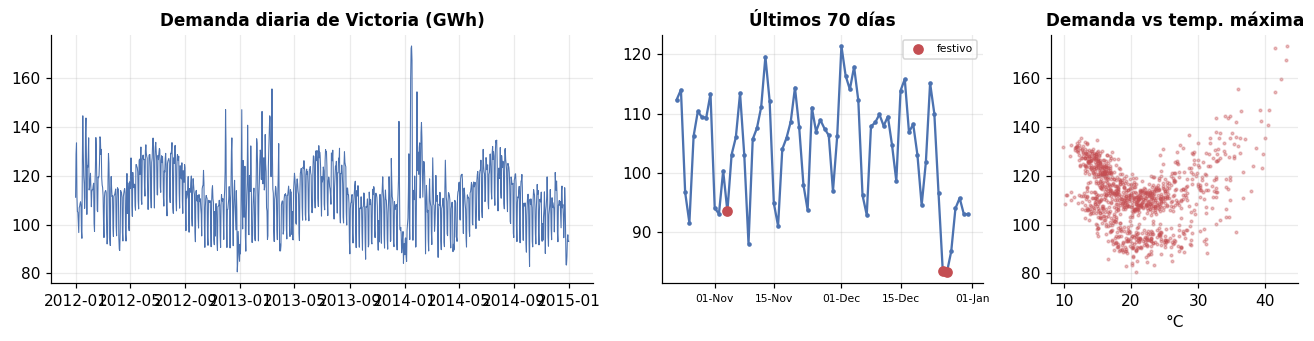

Correlación lineal demanda-temperatura: 0.04
Consumo medio en festivos: 97.5 GWh  vs  días normales: 112.4 GWh
Días de mayor demanda: 2014-01-16 (173 GWh), 2014-01-15 (172 GWh), 2014-01-17 (167 GWh)


In [3]:
# === 1.3 Descarga y preparación de los datos ================================
import urllib.request, pyreadr

def descargar(urls, destino):
    # Prueba varias URLs; la primera está fijada a una versión concreta (reproducibilidad)
    for u in urls:
        try:
            urllib.request.urlretrieve(u, destino)
            return destino
        except Exception as e:
            print(f"  no se pudo descargar {u}: {e}")
    raise RuntimeError("No hay conexión con GitHub. Revisa tu conexión a internet.")

URLS_VIC = [
    "https://raw.githubusercontent.com/tidyverts/tsibbledata/ccfcb321bb4f0e12b7287f5a8f752097e35a20a5/data/vic_elec.rda",
    "https://raw.githubusercontent.com/tidyverts/tsibbledata/master/data/vic_elec.rda",
]
crudo = pyreadr.read_r(descargar(URLS_VIC, "vic_elec.rda"))["vic_elec"]
print(f"Datos originales: {len(crudo):,} registros cada 30 minutos")
display(crudo.head(3))

# Agregación diaria: MW durante media hora x 0.5 h = MWh  ->  / 1000 = GWh
crudo["Date"] = pd.to_datetime(crudo["Date"])
df = (crudo.groupby("Date")
            .agg(demanda=("Demand", lambda x: x.sum()*0.5/1000),
                 temperatura=("Temperature", "max"),
                 festivo=("Holiday", "max"))
            .asfreq("D"))
df["festivo"] = df["festivo"].astype(int)
df.index.name = "fecha"
print(f"\nSerie diaria: {df.index.min().date()} a {df.index.max().date()}  |  {len(df)} días  |  "
      f"valores faltantes: {int(df.isna().sum().sum())}")
display(df.describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2.2, 1.3, 1]})
axes[0].plot(df.index, df["demanda"], color=COLORES["train"], lw=0.7)
axes[0].set_title("Demanda diaria de Victoria (GWh)")
ult = df.iloc[-70:]
axes[1].plot(ult.index, ult["demanda"], color=COLORES["train"], marker="o", ms=2)
fest = ult[ult["festivo"] == 1]
axes[1].scatter(fest.index, fest["demanda"], color=COLORES["pred"], zorder=3, label="festivo")
axes[1].set_title("Últimos 70 días"); axes[1].legend(fontsize=7)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b")); axes[1].tick_params(axis="x", labelsize=7)
axes[2].scatter(df["temperatura"], df["demanda"], s=3, alpha=0.35, color=COLORES["pred"])
axes[2].set_title("Demanda vs temp. máxima"); axes[2].set_xlabel("°C")
plt.tight_layout(); plt.show()

print(f"Correlación lineal demanda-temperatura: {df['demanda'].corr(df['temperatura']):.2f}")
print(f"Consumo medio en festivos: {df.loc[df.festivo==1, 'demanda'].mean():.1f} GWh  vs  "
      f"días normales: {df.loc[df.festivo==0, 'demanda'].mean():.1f} GWh")
print("Días de mayor demanda:", ", ".join(f"{d.date()} ({v:.0f} GWh)" for d, v in df["demanda"].nlargest(3).items()))

**Lectura** (cuatro hechos que guiarán todo el modelado):

1. **Estacionalidad semanal muy marcada:** sábados y domingos se consume ~13 % menos que entre semana.
2. **Estacionalidad anual con dos picos:** invierno (calefacción, junio-agosto) y verano (aire acondicionado). Los mínimos están en primavera y otoño.
3. **Relación en U con la temperatura.** La correlación lineal es **casi cero** y, sin embargo, la temperatura es una de las variables más influyentes. Es el ejemplo perfecto de que **correlación ≈ 0 no significa ausencia de relación**: solo significa que la relación no es una recta. Los días de mayor demanda son del 14 al 16 de enero de 2014, durante la **ola de calor de Melbourne**, con máximas superiores a 41 °C.
4. **Los festivos** reducen el consumo como si fueran domingo. Y el periodo de test contiene Navidad.

Además hay una **ligera tendencia a la baja** (≈ 1 % anual), coherente con la mejora en eficiencia energética y con la expansión de paneles solares en tejados, que reducen la demanda sobre la red.

Una **descomposición STL** separa los componentes de forma robusta a valores atípicos como la ola de calor:

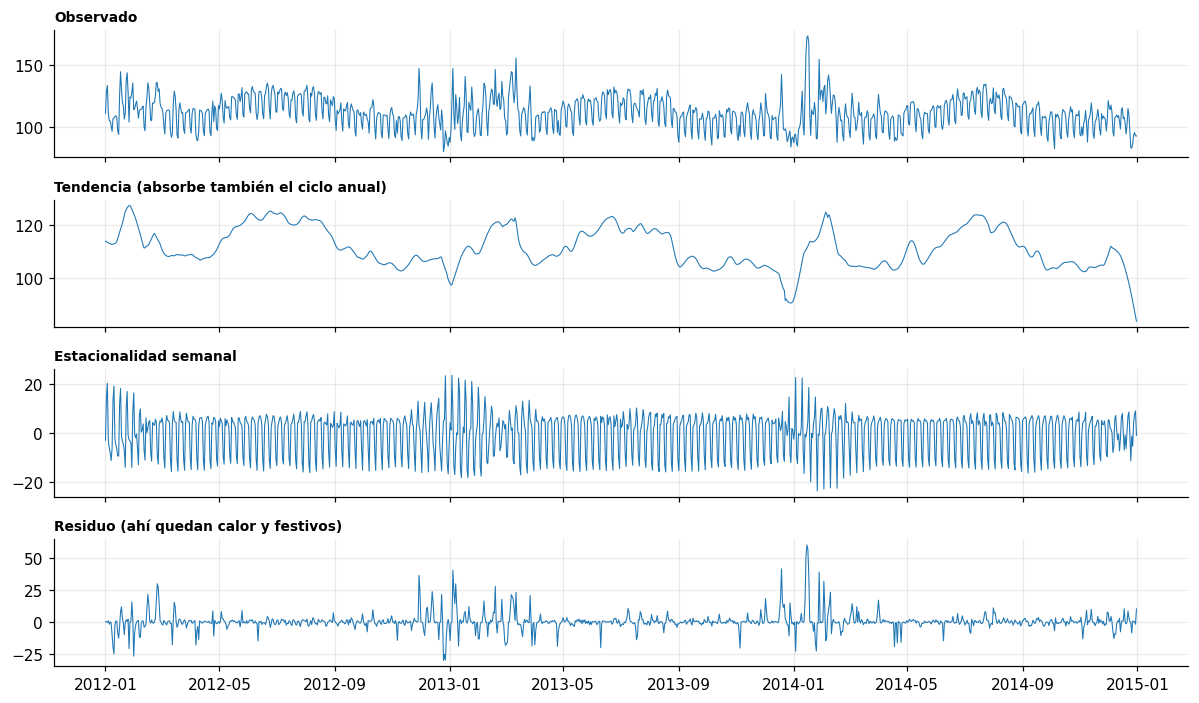

In [4]:
# === 1.4 Descomposición STL ==================================================
from statsmodels.tsa.seasonal import STL
stl = STL(df["demanda"], period=7, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 6.5), sharex=True)
for ax, s, tit in zip(axes, [df["demanda"], stl.trend, stl.seasonal, stl.resid],
                      ["Observado", "Tendencia (absorbe también el ciclo anual)", "Estacionalidad semanal", "Residuo (ahí quedan calor y festivos)"]):
    ax.plot(s.index, s.values, lw=0.7); ax.set_title(tit, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 1.5 Estacionariedad y autocorrelación

Una serie es **estacionaria** si su media, su varianza y su autocorrelación no dependen del momento en que la observas. ARIMA la necesita; se consigue **diferenciando**: $\nabla y_t = y_t - y_{t-1}$ (quita tendencia) o $\nabla_m y_t = y_t - y_{t-m}$ (quita estacionalidad).

Dos pruebas complementarias, **con hipótesis nulas invertidas** (confusión clásica):
- **ADF**: $H_0$ = *no estacionaria*. $p<0.05$ → estacionaria.
- **KPSS**: $H_0$ = *estacionaria*. $p<0.05$ → no estacionaria.

**ACF** (correlación entre $y_t$ y $y_{t-k}$) y **PACF** (lo mismo, descontando los rezagos intermedios) son la huella digital de la serie:

| Patrón | Interpretación |
|---|---|
| ACF decae muy lento | No estacionaria → diferenciar |
| PACF se corta en $p$ | Componente AR($p$) |
| ACF se corta en $q$ | Componente MA($q$) |
| Picos en $m, 2m, 3m$ | Estacionalidad de periodo $m$ |

original                   ADF p=0.010 -> estacionaria     KPSS p=0.015 -> NO estacionaria
diff estacional (1-B^7)    ADF p=0.000 -> estacionaria     KPSS p=0.100 -> estacionaria


C:\Users\criju\AppData\Local\Temp\ipykernel_20296\960161365.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  p_adf, p_kpss = adfuller(serie, autolag="AIC")[1], kpss(serie, regression="c", nlags="auto")[1]


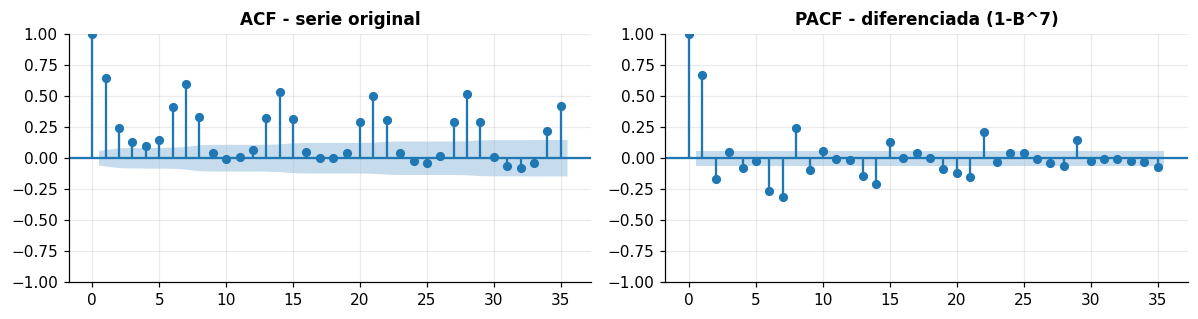


En la serie original las pruebas se CONTRADICEN: la evidencia es débil y conviene
mirar el gráfico. Tras la diferencia estacional, ambas coinciden en que es estacionaria.
ACF: picos en 7, 14, 21, 28 -> estacionalidad semanal. Usaremos D=1 (estacional) y d=0.


In [5]:
# === 1.5 Pruebas de estacionariedad + ACF/PACF ===============================
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def test_estacionariedad(serie, nombre):
    serie = pd.Series(serie).dropna()
    p_adf, p_kpss = adfuller(serie, autolag="AIC")[1], kpss(serie, regression="c", nlags="auto")[1]
    v_adf  = "estacionaria" if p_adf  < 0.05 else "NO estacionaria"
    v_kpss = "estacionaria" if p_kpss > 0.05 else "NO estacionaria"
    print(f"{nombre:<26} ADF p={p_adf:.3f} -> {v_adf:<16} KPSS p={p_kpss:.3f} -> {v_kpss}")

y = df["demanda"]
test_estacionariedad(y,          "original")
test_estacionariedad(y.diff(7),  "diff estacional (1-B^7)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
plot_acf(y, lags=35, ax=axes[0], title="ACF - serie original")
plot_pacf(y.diff(7).dropna(), lags=35, ax=axes[1], title="PACF - diferenciada (1-B^7)", method="ywm")
plt.tight_layout(); plt.show()
print("\nEn la serie original las pruebas se CONTRADICEN: la evidencia es débil y conviene")
print("mirar el gráfico. Tras la diferencia estacional, ambas coinciden en que es estacionaria.")
print("ACF: picos en 7, 14, 21, 28 -> estacionalidad semanal. Usaremos D=1 (estacional) y d=0.")


## 2. Cómo evaluar un pronóstico 

**Partición cronológica:** entrenamos con el pasado y evaluamos con las **últimas 4 semanas** ($h=28$ días), un horizonte habitual en la planificación de un operador eléctrico. Es la partición más simple (un solo corte en dos partes); en la sección 4.2 veremos esquemas más robustos que recorren toda la serie.

**Métricas** (con $e_t = y_t - \hat y_t$):

| Métrica | Fórmula | Comentario |
|---|---|---|
| MAE | $\frac{1}{n}\sum\lvert e_t\rvert$ | En GWh, fácil de interpretar |
| RMSE | $\sqrt{\frac{1}{n}\sum e_t^2}$ | Castiga los errores grandes |
| MAPE | $\frac{100}{n}\sum\lvert e_t/y_t\rvert$ | En %, pero **explota si $y_t\approx 0$** |
| **MASE** | $\dfrac{\text{MAE}}{\text{MAE del naive estacional en train}}$ | **La mejor para comparar** |

**MASE < 1** → tu modelo supera a "repetir la semana pasada". **MASE ≥ 1** → tu modelo pierde contra una línea de código.

In [6]:
# === 2.1 Partición y métricas ================================================
H, M = 28, 7                           # horizonte y periodo estacional
train_full, test = df.iloc[:-H], df.iloc[-H:]
y_tr, y_test = train_full["demanda"], test["demanda"].values
print(f"train: {train_full.index[0].date()} -> {train_full.index[-1].date()} ({len(train_full)} días)")
print(f"test : {test.index[0].date()} -> {test.index[-1].date()} ({len(test)} días)")

def mae(y, p):  return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p))**2)))
def mape(y, p): return float(np.mean(np.abs((np.asarray(y) - np.asarray(p))/np.asarray(y)))*100)

def escala_mase(serie_train, m=M):
    v = np.asarray(serie_train, float)
    return float(np.mean(np.abs(v[m:] - v[:-m])))     # MAE del naive estacional en train

ESCALA_MASE = escala_mase(y_tr)

def evaluar(y_true, y_pred, nombre, escala=None):
    esc = ESCALA_MASE if escala is None else escala
    return {"modelo": nombre, "MAE": round(mae(y_true, y_pred), 2),
            "RMSE": round(rmse(y_true, y_pred), 2), "MAPE%": round(mape(y_true, y_pred), 2),
            "MASE": round(mae(y_true, y_pred)/esc, 3)}

RESULTADOS = []
print(f"\nEscala MASE = {ESCALA_MASE:.2f} GWh (error típico de repetir la semana anterior)")

train: 2012-01-01 -> 2014-12-03 (1068 días)
test : 2014-12-04 -> 2014-12-31 (28 días)

Escala MASE = 7.07 GWh (error típico de repetir la semana anterior)



## 3. Modelos clásicos

Los modelos clásicos describen la serie como un **proceso estocástico** con pocos parámetros interpretables. Veremos solo los más simples.

### 3.1 Métodos de referencia (*baselines*)

| Método | Pronóstico | Idea |
|---|---|---|
| Media | $\hat y_{T+h} = \bar y$ | Todo es ruido alrededor de una media |
| Naive | $\hat y_{T+h} = y_T$ | Mañana será como hoy |
| Naive estacional | $\hat y_{T+h} = y_{T+h-m}$ | Repetir el último ciclo completo |

Parecen triviales, pero son **obligatorios**: si un modelo no les gana, no sirve.

In [7]:
# === 3.1 Baselines ===========================================================
def f_media(hist, h):  return np.repeat(hist["demanda"].mean(), h)
def f_naive(hist, h):  return np.repeat(hist["demanda"].iloc[-1], h)
def f_snaive(hist, h, m=M):
    return np.tile(hist["demanda"].values[-m:], int(np.ceil(h/m)))[:h]

for nombre, fn in {"Media": f_media, "Naive": f_naive, "Naive estacional": f_snaive}.items():
    RESULTADOS.append(evaluar(y_test, fn(train_full, H), nombre))
display(pd.DataFrame(RESULTADOS).set_index("modelo"))

,MAE,RMSE,MAPE%,MASE
modelo,,,,
Media,11.00,13.91,11.67,1.555
Naive,12.34,15.31,13.06,1.744
Naive estacional,9.65,12.29,10.00,1.364


## 3.2 Suavizado exponencial y SARIMA

**Suavizado exponencial.** El pronóstico es un promedio ponderado del pasado, con pesos que decaen exponencialmente: lo reciente importa más. El caso simple es

$$\hat y_{t+1} = \alpha\, y_t + (1-\alpha)\,\hat y_t, \qquad 0<\alpha<1.$$

**Holt-Winters** mantiene tres estados que se actualizan con esa misma lógica: nivel, tendencia y estacionalidad.

**ARIMA($p,d,q$).** Combina tres ideas:
- **AR($p$), autorregresivo:** $y_t$ depende de sus $p$ valores anteriores, $y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$. Modela inercia.
- **I($d$), integrado:** se diferencia la serie $d$ veces para volverla estacionaria.
- **MA($q$), media móvil:** $y_t$ depende de los $q$ errores anteriores, $y_t = \mu + \varepsilon_t + \theta_1\varepsilon_{t-1} + \dots$ Modela shocks que se disipan.

**SARIMA($p,d,q$)($P,D,Q$)$_m$** repite la misma estructura en los rezagos estacionales $m, 2m, \dots$ Aquí usaremos $m=7$ y $D=1$ (diferencia semanal), como indicaron las pruebas de la sección 1.5.

Ambos modelos son **lineales**, se ajustan **a una sola serie** y solo usan su propio pasado.

,MAE,RMSE,MAPE%,MASE
modelo,,,,
Holt-Winters,8.56,11.95,9.05,1.211
"SARIMA(1,0,1)(1,1,1)7",8.72,12.07,9.21,1.233
Naive estacional,9.65,12.29,10.00,1.364
Media,11.00,13.91,11.67,1.555
Naive,12.34,15.31,13.06,1.744


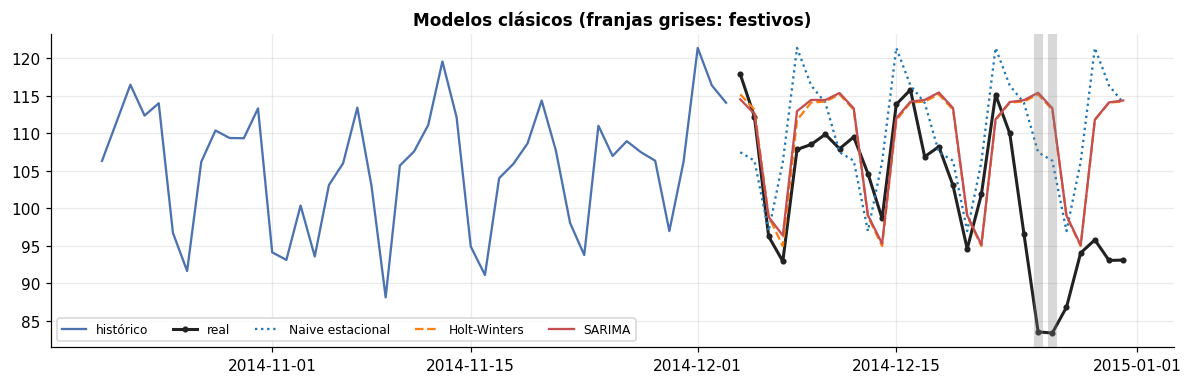

Mejoran al baseline, pero solo conocen el pasado de la demanda: no saben que viene
Navidad ni qué temperatura hará. Con machine learning es natural darles esa información.


In [8]:
# === 3.2 Holt-Winters y SARIMA ===============================================
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

def ajustar(serie, orden=(1,0,1), orden_s=(1,1,1,M), exog=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(serie, exog=exog, order=orden, seasonal_order=orden_s, trend="c",
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

hw = ExponentialSmoothing(y_tr, trend="add", damped_trend=True, seasonal="add",
                          seasonal_periods=M, initialization_method="estimated").fit()
p_hw = hw.forecast(H).values
sarima = ajustar(y_tr)
p_sarima = sarima.get_forecast(H).predicted_mean.values
RESULTADOS.append(evaluar(y_test, p_hw, "Holt-Winters"))
RESULTADOS.append(evaluar(y_test, p_sarima, "SARIMA(1,0,1)(1,1,1)7"))
display(pd.DataFrame(RESULTADOS).set_index("modelo").sort_values("MASE"))

fig, ax = plt.subplots()
ax.plot(train_full.index[-45:], y_tr.iloc[-45:], color=COLORES["train"], label="histórico")
ax.plot(test.index, y_test, color=COLORES["real"], lw=2, marker="o", ms=3, label="real")
ax.plot(test.index, f_snaive(train_full, H), ls=":", label="Naive estacional")
ax.plot(test.index, p_hw, ls="--", label="Holt-Winters")
ax.plot(test.index, p_sarima, color=COLORES["pred"], label="SARIMA")
for f in test.index[test["festivo"] == 1]:
    ax.axvline(f, color="gray", alpha=0.3, lw=6)
ax.set_title("Modelos clásicos (franjas grises: festivos)"); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()
print("Mejoran al baseline, pero solo conocen el pasado de la demanda: no saben que viene")
print("Navidad ni qué temperatura hará. Con machine learning es natural darles esa información.")

## 4. Machine Learning para series de tiempo

Los métodos clásicos de series de tiempo, como ARIMA, SARIMA o ETS, modelan explícitamente
la estructura estadística de la serie. En cambio, los métodos de **Machine Learning (ML)**
permiten aprender relaciones más flexibles directamente a partir de los datos.

En el contexto de series de tiempo, un problema de predicción puede formularse como:

$$
y_{t+1} = f(y_t, y_{t-1}, \ldots, y_{t-p+1})
$$

donde:

- $y_t$ representa el valor de la serie en el instante $t$.
-$p$ es el tamaño de la ventana temporal utilizada como entrada.
- $f(\cdot)$ es una función aprendida a partir de los datos.


## 4.1 Redes neuronales

Las redes neuronales artificiales son modelos capaces de aproximar funciones no lineales
a partir de ejemplos.

Una neurona puede representarse de forma simplificada como:

$$
z = \mathbf{w}^T\mathbf{x} + b
$$

$$
\hat{y} = \sigma(z)
$$

donde:

- $\mathbf{x}$ representa las variables de entrada.
- $\mathbf{w}$ son los pesos aprendidos.
- $b$ es el sesgo.
- $\sigma$ es una función de activación.
- $\hat{y}$ es la predicción del modelo.

Para una serie de tiempo podemos utilizar una red neuronal para aprender una función:

$$
\hat{y}_{t+1} =
f(y_t,y_{t-1},\ldots,y_{t-p+1})
$$

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers



ModuleNotFoundError: No module named 'tensorflow'

---
## 5. Resumen: modelos clásicos vs machine learning 

### ¿Qué modela cada enfoque y qué supone?

| Aspecto | Clásicos (media, naive, Holt-Winters, SARIMA) | Machine learning (LightGBM, redes neuronales) |
|---|---|---|
| **Qué modelan** | El **proceso** que genera la serie: una ecuación explícita de cómo $y_t$ depende de sus valores y errores pasados | Una **función** aprendida de ejemplos: ventana de entrada + variables → valores futuros, sin ecuación predefinida |
| **Forma de la relación** | Lineal | No lineal; descubre interacciones solo |
| **Estacionariedad** | La **exigen**: se consigue diferenciando | No la exigen formalmente, pero suponen que la relación entre variables y objetivo **se mantiene estable** en el tiempo |
| **Residuos** | Ruido blanco con varianza constante (y normalidad, para los intervalos) | Sin supuesto explícito |
| **Dependencia temporal** | La modelan explícitamente (AR, MA) | El algoritmo trata las filas como independientes: la dependencia entra por los rezagos, y por eso la **validación debe ser temporal** |
| **Datos necesarios** | Pocos (decenas o cientos de puntos) | Muchos (cientos o miles de ventanas); mejor aún con muchas series a la vez |
| **Variables externas** | Posibles (SARIMAX), con efecto lineal | Naturales: cualquier cantidad, con efectos no lineales |
| **Tendencia y extrapolación** | Extrapolan tendencias | Los árboles **no extrapolan** más allá de lo visto: hay que diferenciar o modelar la tendencia aparte |
| **Pronóstico multi-paso** | Nativo: la ecuación se proyecta | Hay que elegir una estrategia: recursiva, directa o multi-salida |
| **Incertidumbre** | Intervalos analíticos, válidos si se cumplen los supuestos | No son nativos: regresión por cuantiles o *conformal prediction* |
| **Interpretabilidad** | Alta: cada coeficiente tiene significado | Media o baja: importancia de variables, SHAP |
| **Trabajo principal** | Elegir órdenes $(p,d,q)$ y transformaciones | Construir ventanas y variables sin fugas de información |
| **Alcance** | Un modelo por serie (**local**) | Un modelo para muchas series (**global**) |

## ¿Cuál elegir?

- **Pocos datos, una sola serie, se necesita explicar el modelo:** clásicos. Son rápidos, estables y difíciles de romper.
- **Muchos datos, variables externas importantes (clima, festivos, precios) o muchas series relacionadas:** machine learning.
- **En la práctica** se usan juntos: el clásico como referencia exigente, el de ML para ganar precisión, y a menudo un **ensamble** de ambos.

## Lo que deberías llevarte

1. **El baseline manda.** Si no le ganas al naive estacional (MASE < 1), no tienes modelo.
2. **Nunca barajes una serie de tiempo.** Las ventanas vecinas se solapan: la validación aleatoria premia la memoria, no la capacidad de predecir. En la caminata aleatoria prometió un imposible.
3. **Valida con varios cortes temporales.** Ventana expansiva o deslizante, con hueco si las salidas se solapan. Un solo corte da una cifra que depende de la suerte.
4. **La información pesa más que el algoritmo.** Calendario, temperatura y festivos mejoraron más a los modelos que cualquier cambio de arquitectura.
5. **Clásicos y ML no compiten: se complementan.** Entender los supuestos de cada uno te dice cuándo confiar en él.

**Para seguir:** *Forecasting: Principles and Practice* (Hyndman & Athanasopoulos, gratis en `otexts.com/fpp3`) · librerías `statsforecast`, `mlforecast` y `neuralforecast` (Nixtla), que automatizan todo lo visto aquí · para intervalos de predicción con garantías, *conformal prediction* (Angelopoulos & Bates, 2023).